# 02 — Model Training, Evaluation and Prediction

**Objective:** Build three regression models, compare their validation performance, select a model using cross-validation, save the final fitted pipeline, and create predictions for Kaggle's `test.csv`.

## Key concepts
- **Feature matrix (X):** property characteristics used as inputs.
- **Target (y):** `SalePrice`, the value to predict.
- **Train/validation split:** hold out part of the labelled training data to estimate performance on unseen examples.
- **Cross-validation:** repeat training/validation across folds to obtain a more stable model-selection score.
- **Pipeline:** keeps imputation, scaling, encoding, and model training together to reduce data leakage.
- **Log target:** `SalePrice` is right-skewed, so models are trained on `log1p(SalePrice)` and predictions are converted back to dollars.

> The Kaggle `test.csv` has no `SalePrice`. Validation metrics are calculated only from an internal split of `train.csv`.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.modeling import train_and_save

summary_path = PROJECT_ROOT / "artifacts" / "summary.json"
model_path = PROJECT_ROOT / "artifacts" / "best_house_price_model.pkl"

if not summary_path.exists() or not model_path.exists():
    print("No trained model found. Training now...")
    summary = train_and_save(PROJECT_ROOT)
else:
    summary = json.loads(summary_path.read_text(encoding="utf-8"))
    print("Loaded the existing training run.")
    print("To retrain after changing the dataset, run: python train_model.py")

print("Selected model:", summary["selected_model"])
display(pd.read_csv(PROJECT_ROOT / "artifacts" / "model_comparison.csv"))

Loaded the existing training run.
To retrain after changing the dataset, run: python train_model.py
Selected model: XGBoost


,Model,CV RMSE,Validation MAE,Validation RMSE,Validation R2
0,XGBoost,28457.580729,15895.870117,27454.653813,0.901731
1,Random Forest,30806.141916,17180.806634,30312.338134,0.880209
2,Linear Regression,58252.503890,15655.022588,24293.819801,0.923055


## 1. Understand the evaluation metrics
- **MAE:** average absolute difference between actual and predicted prices, measured in dollars. Lower is better.
- **RMSE:** square root of mean squared error; large mistakes are penalized more. Lower is better.
- **R²:** proportion of variation in prices explained by the model. Values closer to 1 are generally better; negative values are possible.
- **CV RMSE:** average RMSE across cross-validation folds on the training portion. The project selects the model using this score, not by looking at the holdout result.

In [2]:
results = pd.read_csv(PROJECT_ROOT / "artifacts" / "model_comparison.csv")
display(results.sort_values("CV RMSE"))
print("Best model by CV RMSE:", summary["selected_model"])

,Model,CV RMSE,Validation MAE,Validation RMSE,Validation R2
0,XGBoost,28457.580729,15895.870117,27454.653813,0.901731
1,Random Forest,30806.141916,17180.806634,30312.338134,0.880209
2,Linear Regression,58252.503890,15655.022588,24293.819801,0.923055


Best model by CV RMSE: XGBoost


## 2. Inspect validation charts
The actual-vs-predicted plot should cluster around the diagonal line. Residuals are actual minus predicted prices; a good model should not show a strong systematic pattern.

06_actual_vs_predicted.png


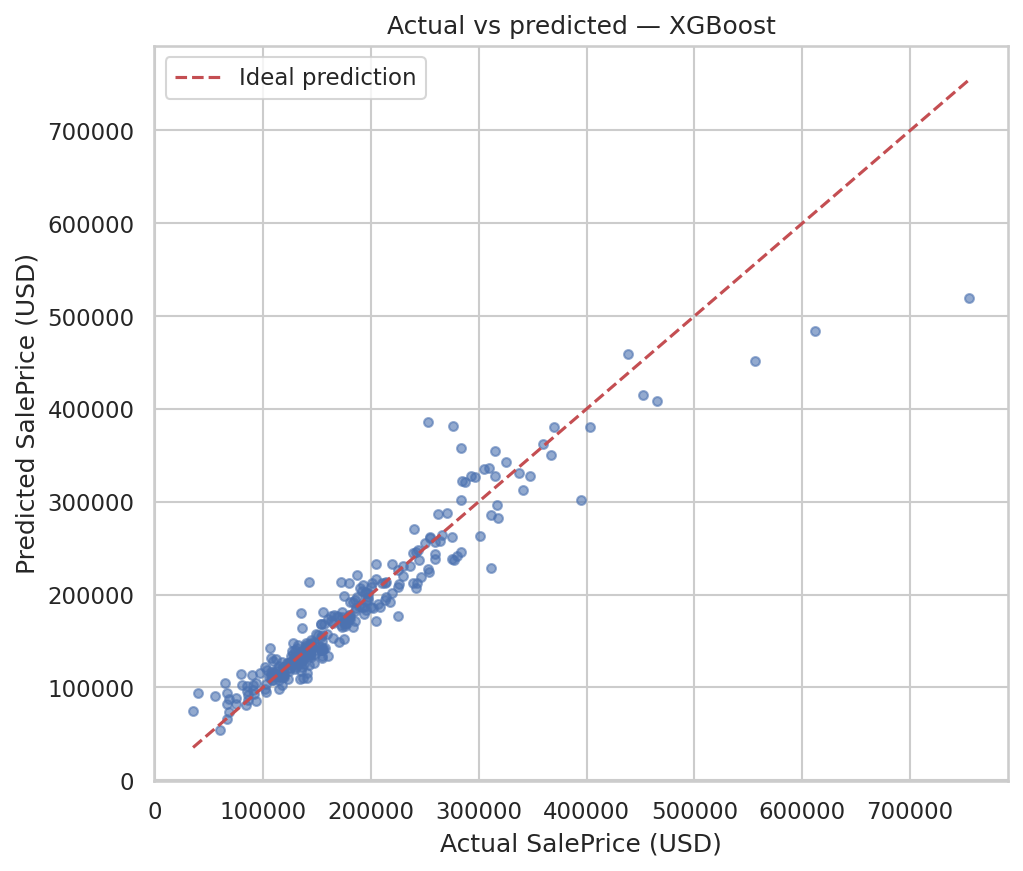

07_residual_distribution.png


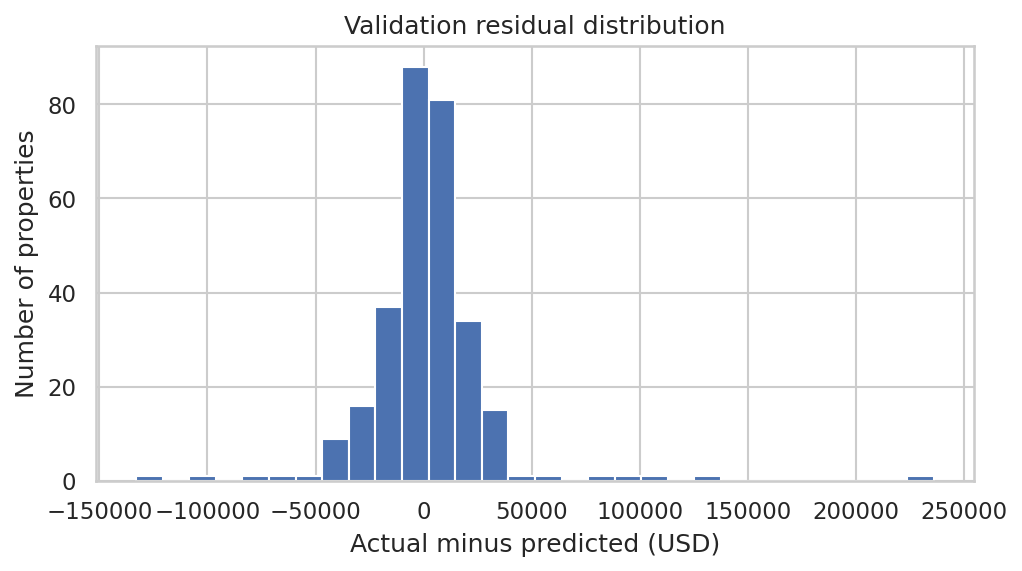

In [6]:
from IPython.display import Image, display as show_image

for filename in ["06_actual_vs_predicted.png", "07_residual_distribution.png"]:
    path = PROJECT_ROOT / "outputs" / "charts" / filename
    if path.exists():
        print(filename)
        show_image(Image(filename=str(path)))

## 3. Kaggle test predictions
The final selected model is refitted on all 1,460 labelled training rows. It predicts `SalePrice` for the 1,459 rows in `test.csv`, producing `submission.csv` with exactly two columns: `Id` and `SalePrice`.

These predictions are not used to calculate validation metrics because the true target values are not supplied.

In [5]:
submission = pd.read_csv(PROJECT_ROOT / "submission.csv")
sample = pd.read_csv(PROJECT_ROOT / "data" / "sample_submission.csv")
print("Submission shape:", submission.shape)
print("Expected sample shape:", sample.shape)
print("Columns match:", submission.columns.tolist() == sample.columns.tolist())
print("IDs match:", submission["Id"].equals(sample["Id"]))
display(submission.head())
print("Predicted price summary:")
display(submission["SalePrice"].describe())

Submission shape: (1459, 2)
Expected sample shape: (1459, 2)
Columns match: True
IDs match: True


,Id,SalePrice
0,1461,123508.39
1,1462,163041.66
2,1463,176841.45
3,1464,192013.67
4,1465,185039.19


Predicted price summary:


count      1459.000000
mean     177879.370555
std       76624.378502
min       48278.640000
25%      127756.690000
50%      157139.450000
75%      208110.275000
max      517010.250000
Name: SalePrice, dtype: float64

## 4. Model artifact and Gradio interface
The fitted preprocessing + regression pipeline is saved to `artifacts/best_house_price_model.pkl`. The Gradio app loads this file and predicts a historical Ames price from user-entered property details.

Run from the project root:
```bash
python app/app.py
```

The interface uses representative training-data values for property characteristics not exposed as input controls. It is an educational demonstration, not a current appraisal.